# Sales Effectiveness — Lead Categorisation

## 1. Project Overview

**Company:** FicZon Inc.  
**Project Reference:** PM-PR-0019  
**Project Category:** Product Sales

### Objective

The objective of this project is to develop a machine learning model that categorises leads into High Potential and Low Potential groups. This will help the sales team prioritise leads and focus its efforts on leads that are more likely to result in successful conversions.

### Project Approach

The project involves data understanding, data cleaning, exploratory data analysis (EDA), feature engineering, model development, model evaluation, and business recommendations.

## Business Problem

FicZon Inc. has experienced a decline in sales effectiveness. Currently, sales leads are categorised manually, which can be time-consuming and may lead to inconsistent assessments.

The objective is to develop a machine learning model that categorises leads into High Potential and Low Potential, helping the sales team prioritise leads more effectively.

In [1]:
!pip install mysql-connector-python pandas

In [2]:
import mysql.connector
import pandas as pd
import numpy as np

In [3]:
import os
connection = mysql.connector.connect(
    host=os.getenv("DB_HOST", "localhost"),
    user=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    database=os.getenv("DB_NAME")
)

print("Database connected successfully!")

Database connected successfully!


cursor = connection.cursor()
cursor.execute("SHOW TABLES")

for table in cursor:
    print(table)

In [4]:
cursor = connection.cursor()
cursor.execute("DESCRIBE data")

for row in cursor.fetchall():
    print(row)

('Created', 'varchar(150)', 'YES', '', None, '')
('Product_ID', 'varchar(150)', 'YES', '', None, '')
('Source', 'varchar(150)', 'YES', '', None, '')
('Mobile', 'varchar(150)', 'YES', '', None, '')
('EMAIL', 'varchar(150)', 'YES', '', None, '')
('Sales_Agent', 'varchar(255)', 'YES', '', None, '')
('Location', 'varchar(255)', 'YES', '', None, '')
('Delivery_Mode', 'varchar(255)', 'YES', '', None, '')
('Status', 'varchar(255)', 'YES', '', None, '')


## 3. Dataset Overview

The dataset contains information about sales leads generated through different sources. It includes details such as lead creation date, product ID, lead source, sales agent, location, delivery mode, and lead status.

The dataset is used to understand lead characteristics and identify patterns that may help predict lead potential.

The initial dataset inspection helps us understand the number of records, available features, data types, and data quality before performing preprocessing and exploratory data analysis.

In [5]:
query = "SELECT * FROM data"
df = pd.read_sql(query,connection)
print("Data downloaded succesfully!")

C:\Users\govar\AppData\Local\Temp\ipykernel_38096\4104478761.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query,connection)


Data downloaded succesfully!


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7422 entries, 0 to 7421
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Created        7422 non-null   object
 1   Product_ID     7422 non-null   object
 2   Source         7422 non-null   object
 3   Mobile         7422 non-null   object
 4   EMAIL          7422 non-null   object
 5   Sales_Agent    7422 non-null   object
 6   Location       7422 non-null   object
 7   Delivery_Mode  7422 non-null   object
 8   Status         7422 non-null   object
dtypes: object(9)
memory usage: 522.0+ KB


In [7]:
df.columns

Index(['Created', 'Product_ID', 'Source', 'Mobile', 'EMAIL', 'Sales_Agent',
       'Location', 'Delivery_Mode', 'Status'],
      dtype='object')

In [8]:
df.shape

(7422, 9)

In [9]:
df.head()

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
0,14-11-2018 10:05,,Website,984XXXXXXX,aXXXXXXX@gmail.com,Sales-Agent-11,,Mode-5,Open
1,14-11-2018 09:22,,Website,XXXXXXX,#VALUE!,Sales-Agent-10,,Mode-5,Open
2,14-11-2018 09:21,,Website,XXXXXXX,dXXXXXXX@yahoo.com,Sales-Agent-10,,Mode-5,Open
3,14-11-2018 08:46,,Website,XXXXXXX,wXXXXXXX@gmail.com,Sales-Agent-10,,Mode-5,Open
4,14-11-2018 07:34,,Website,XXXXXXX,cXXXXXXX@gmail.com,Sales-Agent-10,,Mode-5,Open


In [10]:
df.tail()

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
7417,28-04-2018 09:45,9,Call,,aXXXXXXX@gmail.com,Sales-Agent-6,Mumbai,Mode-4,LOST
7418,28-04-2018 09:43,15,Call,,#VALUE!,Sales-Agent-12,Other Locations,Mode-5,LOST
7419,28-04-2018 09:20,5,Live Chat-Direct,,sXXXXXXX@gmail.com,Sales-Agent-11,Bangalore,Mode-1,Not Responding
7420,28-04-2018 08:04,21,CRM form,,YXXXXXXX@gmail.com,Sales-Agent-4,Other Locations,Mode-1,Just Enquiry
7421,28-04-2018 07:54,25,Website,,cXXXXXXX@gmail.com,Sales-Agent-3,Chennai,Mode-1,CONVERTED


## 4. Data Cleaning and Preprocessing

Data preprocessing is an important step in preparing the dataset for machine learning. It helps improve data quality and ensures that the data is in a suitable format for analysis and model development.

The preprocessing steps include:

- Checking for missing values and duplicate records.
- Standardising inconsistent values in categorical columns.
- Converting the lead creation date into an appropriate datetime format.
- Creating useful features from the existing data.
- Preparing the target variable and transforming categorical features into a format suitable for machine learning.

In [11]:
# Checking for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Checking for duplicate records
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Missing values in each column:
Created          0
Product_ID       0
Source           0
Mobile           0
EMAIL            0
Sales_Agent      0
Location         0
Delivery_Mode    0
Status           0
dtype: int64

Number of duplicate rows:
2


In [12]:
# Checking for blank cells
print("\nBlank cells in each column:")
print(
    df.apply(
        lambda col: col.astype("string").str.strip().eq("").sum()
    )
)

# Checking the unique lead statuses
print("\nUnique lead statuses:")
print(df["Status"].value_counts(dropna=False))


Blank cells in each column:
Created             0
Product_ID         58
Source             17
Mobile           1810
EMAIL               0
Sales_Agent        23
Location           58
Delivery_Mode       0
Status              0
dtype: int64

Unique lead statuses:
Status
Junk Lead               1536
Not Responding          1129
CONVERTED                834
Just Enquiry             760
Potential                708
Long Term                646
In Progress Positive     643
In Progress Negative     626
LOST                     440
Open                      82
converted                 18
Name: count, dtype: int64


In [13]:
# Removing duplicate rows
df = df.drop_duplicates().copy()

# Converting blank strings and whitespace-only cells to missing values
df = df.replace(r'^\s*$', pd.NA, regex=True)

In [14]:
#Standardize text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

#Standardize Status values
df["Status"] = df["Status"].str.strip().str.title()

In [15]:
#Checking the results
print("Dataset shape after removing duplicates:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nStandardized status counts:")
print(df["Status"].value_counts(dropna=False))

Dataset shape after removing duplicates: (7420, 9)

Missing values after cleaning:
Created             0
Product_ID         56
Source             17
Mobile           1810
EMAIL               0
Sales_Agent        23
Location           56
Delivery_Mode       0
Status              0
dtype: int64

Standardized status counts:
Status
Junk Lead               1536
Not Responding          1129
Converted                852
Just Enquiry             760
Potential                708
Long Term                646
In Progress Positive     643
In Progress Negative     626
Lost                     440
Open                      80
Name: count, dtype: int64


In [16]:
print("Available lead statuses:")
print(sorted(df["Status"].unique()))

print("\nTotal records:", len(df))

Available lead statuses:
['Converted', 'In Progress Negative', 'In Progress Positive', 'Junk Lead', 'Just Enquiry', 'Long Term', 'Lost', 'Not Responding', 'Open', 'Potential']

Total records: 7420


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the dataset's structure, identify patterns, and discover useful insights before building a Machine Learning model.

In this Sales Effectiveness project, EDA helps us understand the distribution of leads across different statuses and identify potential factors that may influence lead conversion.

### Objectives of EDA
- Analyze the distribution of lead statuses.
- Identify the most common and least common lead statuses.
- Examine lead sources, products, sales agents, locations, and delivery modes.
- Analyze date and time patterns in lead creation.
- Identify patterns and relationships that may help predict lead potential.

### Lead Status Distribution

The lead status distribution is analyzed using frequency counts, percentages, and a bar chart. This helps us understand how leads are distributed across different stages of the sales process.

The insights obtained from EDA will guide feature engineering, target variable creation, and the development of a Machine Learning model to support lead prioritization.

Lead Status Counts:
Status
Junk Lead               1536
Not Responding          1129
Converted                852
Just Enquiry             760
Potential                708
Long Term                646
In Progress Positive     643
In Progress Negative     626
Lost                     440
Open                      80
Name: count, dtype: int64

Lead Status Percentages:
Status
Junk Lead               20.70
Not Responding          15.22
Converted               11.48
Just Enquiry            10.24
Potential                9.54
Long Term                8.71
In Progress Positive     8.67
In Progress Negative     8.44
Lost                     5.93
Open                     1.08
Name: count, dtype: float64


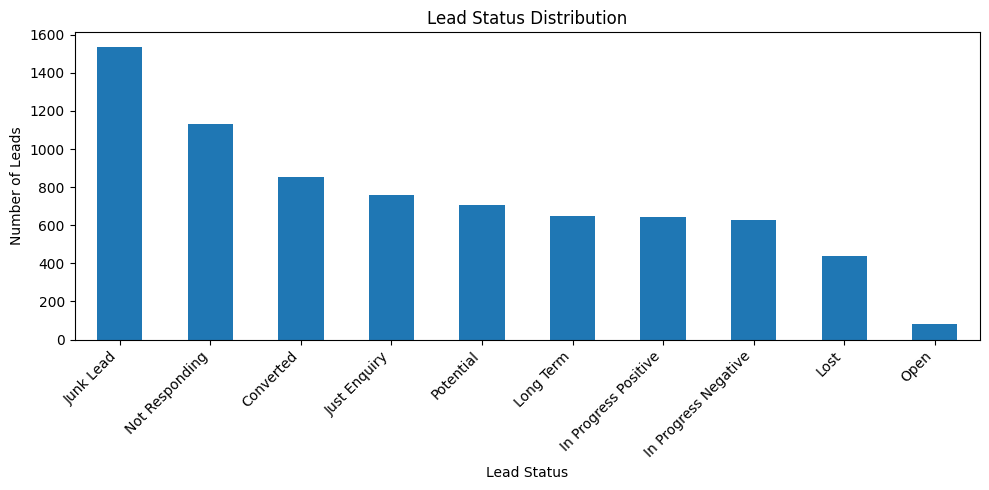

In [17]:
import matplotlib.pyplot as plt

# Count leads in each status
status_counts = df["Status"].value_counts()

# Display counts and percentages
print("Lead Status Counts:")
print(status_counts)

print("\nLead Status Percentages:")
print((status_counts / len(df) * 100).round(2))

# Plot the distribution
plt.figure(figsize=(10, 5))
status_counts.plot(kind="bar")

plt.title("Lead Status Distribution")
plt.xlabel("Lead Status")
plt.ylabel("Number of Leads")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observations: Lead Status Distribution

The dataset contains **7,420 leads** distributed across 10 different lead statuses.

- **Junk Lead** is the most frequent category, with 1,536 leads (20.70%).
- **Not Responding** is the second-largest category, with 1,129 leads (15.22%).
- **Converted** accounts for 852 leads (11.48%), representing leads that successfully converted.
- **Potential** includes 708 leads (9.54%), while **In Progress Positive** includes 643 leads (8.67%).
- **Lost** accounts for 440 leads (5.93%).
- **Open** is the smallest category, with 80 leads (1.08%).

Overall, Junk Lead and Not Responding together account for approximately 35.92% of the dataset. The distribution shows that leads are spread across multiple stages of the sales process.

These findings highlight the importance of analyzing lead sources, products, sales agents, and other available features to identify patterns associated with successful conversions.

Top 15 Lead Sources by Number of Leads:
Source
Call                        2547
Live Chat-Direct            1834
Website                     1592
Live Chat-Google Organic     274
Live Chat -PPC               249
Live Chat-Blog               237
Customer Referral            180
US Website                   137
Just Dial                     56
Existing Client               51
Personal Contact              50
Live Chat-CPC                 50
By Recommendation             32
CRM form                      23
Existing Customer             22
Name: count, dtype: int64


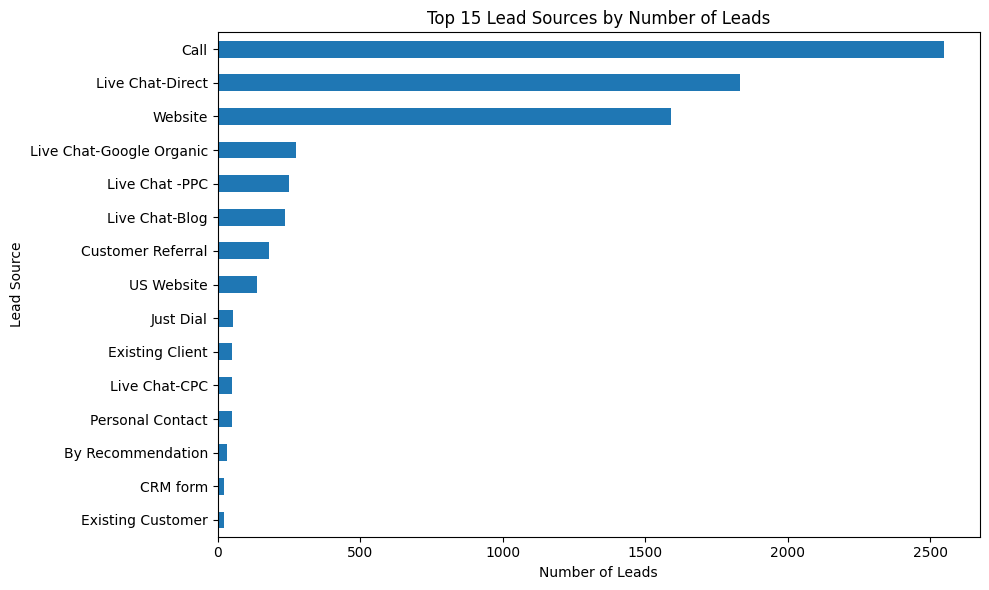

In [18]:
# Lead source analysis
# Analyzing the number of leads from each source
source_counts = df["Source"].fillna("Unknown").value_counts()

print("Top 15 Lead Sources by Number of Leads:")
print(source_counts.head(15))

# Visualizing the top 15 sources
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
source_counts.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Lead Sources by Number of Leads")
plt.xlabel("Number of Leads")
plt.ylabel("Lead Source")
plt.tight_layout()
plt.show()

### Observations: Lead Source Analysis

The lead source analysis shows that leads originate from multiple channels.

- **Call** is the largest lead source, contributing 2,547 leads.
- **Live Chat-Direct** is the second-largest source, with 1,834 leads.
- **Website** contributes 1,592 leads.
- Other notable sources include Live Chat-Google Organic (274), Live Chat-PPC (249), and Live Chat-Blog (237).
- Customer Referral contributes 180 leads, while Existing Client contributes 51 leads.
- CRM form and Existing Customer contribute 23 and 22 leads, respectively, among the top 15 sources.

**Conclusion:** Call, Live Chat-Direct, and Website are the three largest lead acquisition channels by volume. Further analysis is needed to determine which sources generate the highest proportion of converted leads, because lead volume alone does not indicate lead quality.

These findings will help identify which acquisition channels may be useful for improving sales effectiveness.

Top 15 Products by Number of Leads:
Product_ID
18         1711
15         1518
19         1189
9           992
27          739
5           487
10          168
1           105
20          102
25           90
21           66
Unknown      56
2            38
12           36
26           31
Name: count, dtype: int64


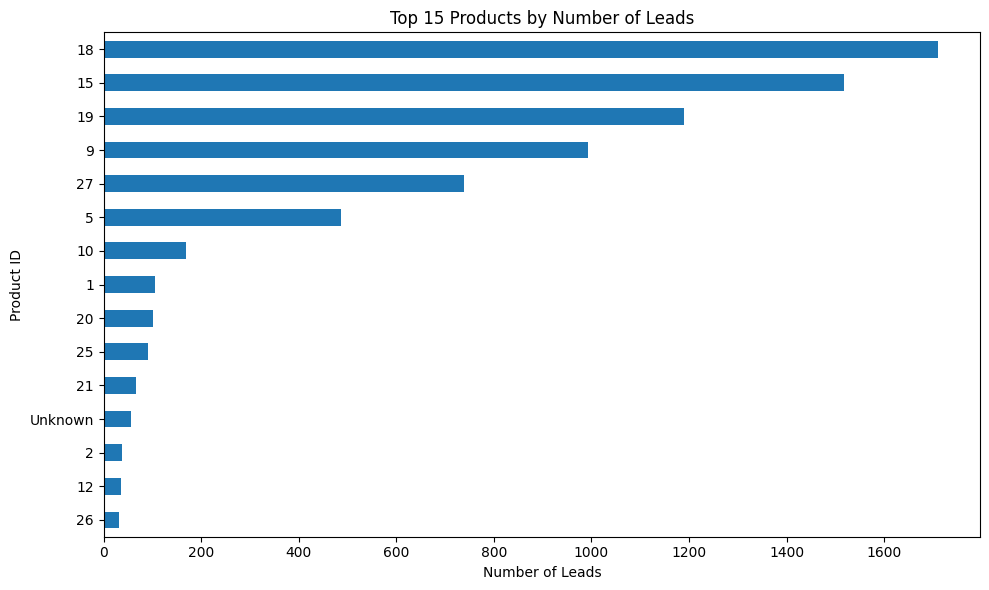

In [19]:
# Product analysis
# Analyzing the number of leads for each product
product_counts = df["Product_ID"].fillna("Unknown").value_counts()

print("Top 15 Products by Number of Leads:")
print(product_counts.head(15))

# Visualizing the top 15 products
plt.figure(figsize=(10, 6))
product_counts.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Products by Number of Leads")
plt.xlabel("Number of Leads")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

### Observations: Product Analysis

The product analysis shows that lead volume varies considerably across products.

- **Product ID 18** has the highest number of leads, with 1,711.
- **Product ID 15** ranks second, with 1,518 leads.
- **Product ID 19** ranks third, with 1,189 leads.
- Product IDs 9 and 27 received 992 and 739 leads, respectively.
- Product IDs 5 and 10 received 487 and 168 leads, respectively.
- There are 56 records with a missing Product ID.

**Conclusion:** Product IDs 18, 15, and 19 account for the largest lead volumes. However, a higher number of leads does not necessarily mean a higher conversion rate. Further analysis of product-wise conversion outcomes is required to identify which products generate better-quality leads.

Lead Counts by Sales Agent:
Sales_Agent
Sales-Agent-4     1500
Sales-Agent-11    1420
Sales-Agent-5     1190
Sales-Agent-9      879
Sales-Agent-3      781
Sales-Agent-7      736
Sales-Agent-2      389
Sales-Agent-12     269
Sales-Agent-6      114
Sales-Agent-8       68
Sales-Agent-10      47
Unknown             23
Sales-Agent-1        4
Name: count, dtype: int64


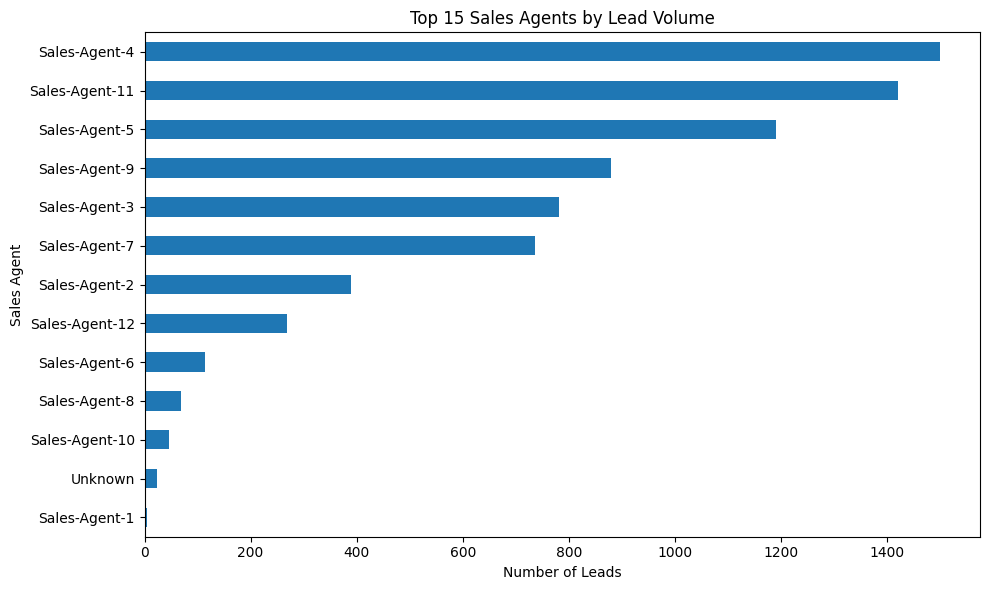

In [20]:
# Sales Agent Analysis
# Analyzing lead volume by sales agent
agent_counts = df["Sales_Agent"].fillna("Unknown").value_counts()

print("Lead Counts by Sales Agent:")
print(agent_counts)

# Visualizing the top 15 sales agents
plt.figure(figsize=(10, 6))
agent_counts.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Sales Agents by Lead Volume")
plt.xlabel("Number of Leads")
plt.ylabel("Sales Agent")
plt.tight_layout()
plt.show()

### Observations: Sales Agent Analysis

The sales agent analysis shows that the number of leads assigned to each sales agent varies considerably.

- **Sales-Agent-4** handles the highest number of leads, with 1,500.
- **Sales-Agent-11** handles 1,420 leads, followed by **Sales-Agent-5** with 1,190 leads.
- Sales-Agent-9 and Sales-Agent-3 handle 879 and 781 leads, respectively.
- Sales-Agent-7 handles 736 leads, while Sales-Agent-2 handles 389 leads.
- Sales-Agent-1 has only 4 leads, and 23 records have a missing Sales Agent value.

**Conclusion:** Sales-Agent-4, Sales-Agent-11, and Sales-Agent-5 have the highest lead volumes. However, lead volume alone does not measure sales effectiveness. Conversion rates should also be compared to understand which agents are more successful at converting leads.

Lead Counts by Location:
Location
Other Locations    2500
Bangalore          2084
Chennai             909
Hyderabad           528
Delhi               471
Mumbai              402
Pune                142
UAE                  79
Trivandrum           58
Unknown              56
Kolkata              55
USA                  45
UK                   41
AUSTRALIA            25
Singapore            17
Malaysia              4
EUROPE                3
Howrah                1
Name: count, dtype: int64


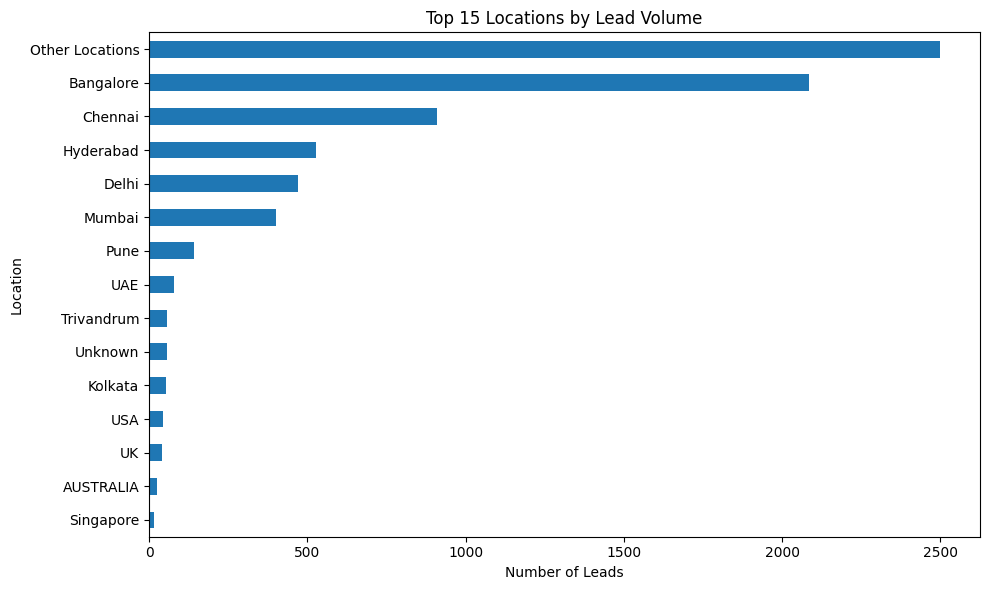

In [21]:
# Location Analysis
# Analyzing lead volume by location
location_counts = df["Location"].fillna("Unknown").value_counts()

print("Lead Counts by Location:")
print(location_counts)

# Visualizing the top 15 locations
plt.figure(figsize=(10, 6))
location_counts.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Locations by Lead Volume")
plt.xlabel("Number of Leads")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

### Observations: Location Analysis

The location analysis shows that leads originate from multiple geographical locations.

- **Other Locations** contributes the highest number of leads, with 2,500.
- **Bangalore** is the second-largest location, with 2,084 leads.
- **Chennai** contributes 909 leads, followed by **Hyderabad** with 528 and **Delhi** with 471.
- Mumbai contributes 402 leads, while Pune contributes 142.
- International locations such as UAE, USA, UK, Australia, Singapore, and Malaysia contribute smaller numbers of leads.
- There are 56 records with an unknown or missing location.

**Conclusion:** Other Locations and Bangalore account for the largest lead volumes. The distribution suggests that lead acquisition is concentrated in a few major location categories. Further analysis of location-wise conversion rates is needed to determine whether these locations also produce higher-quality leads.

Lead Counts by Delivery Mode:
Delivery_Mode
Mode-5    2973
Mode-1    2627
Mode-3    1688
Mode-4     121
Mode-2      11
Name: count, dtype: int64


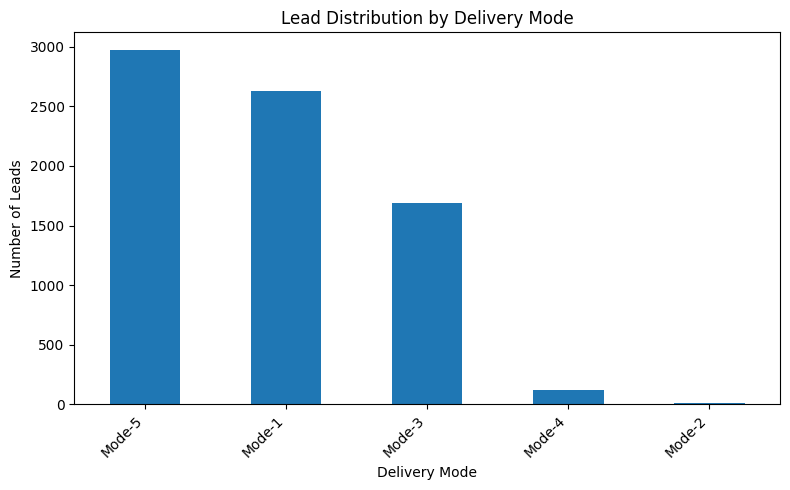

In [22]:
# Delivery Mode Analysis
# Analyze lead volume by delivery mode
delivery_counts = df["Delivery_Mode"].value_counts()

print("Lead Counts by Delivery Mode:")
print(delivery_counts)

# Visualize delivery mode distribution
plt.figure(figsize=(8, 5))
delivery_counts.plot(kind="bar")

plt.title("Lead Distribution by Delivery Mode")
plt.xlabel("Delivery Mode")
plt.ylabel("Number of Leads")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observations: Delivery Mode Analysis

The delivery mode analysis shows that leads are distributed across five delivery modes.

- **Mode-5** has the highest number of leads, with 2,973.
- **Mode-1** ranks second, with 2,627 leads.
- **Mode-3** accounts for 1,688 leads.
- **Mode-4** has 121 leads, while **Mode-2** has only 11 leads.

**Conclusion:** Most leads are associated with Mode-5, Mode-1, and Mode-3. These three modes account for the majority of records in the dataset. Further analysis of conversion rates by delivery mode is needed to determine whether delivery mode is associated with lead quality.

In [23]:
# Lead Creation Date and Time Analysis

# Convert Created to datetime format using day-first parsing
df["Created"] = pd.to_datetime(
    df["Created"],
    dayfirst=True,
    errors="coerce"
)

# Check date quality
print("Invalid or missing dates:", df["Created"].isna().sum())

# Extract date and time features
df["Month"] = df["Created"].dt.month
df["Day_of_Week"] = df["Created"].dt.day_of_week
df["Day_Name"] = df["Created"].dt.day_name()
df["Hour"] = df["Created"].dt.hour

# Display date range
print("\nLead creation date range:")
print("Start:", df["Created"].min())
print("End:", df["Created"].max())

# Analyze leads by month
print("\nLeads by Month:")
print(df["Month"].value_counts().sort_index())

# Analyze leads by day of week
print("\nLeads by Day of Week:")
print(df["Day_Name"].value_counts())

# Analyze leads by hour
print("\nLeads by Hour:")
print(df["Hour"].value_counts().sort_index())

Invalid or missing dates: 0

Lead creation date range:
Start: 2018-04-28 07:54:00
End: 2018-11-14 10:05:00

Leads by Month:
Month
4      115
5     1260
6     1285
7     1157
8     1119
9     1103
10    1000
11     381
Name: count, dtype: int64

Leads by Day of Week:
Day_Name
Monday       1513
Tuesday      1319
Wednesday    1272
Thursday     1096
Friday       1066
Saturday      756
Sunday        398
Name: count, dtype: int64

Leads by Hour:
Hour
0       79
1       46
2       29
3       31
4       29
5       32
6       28
7       46
8       73
9      333
10     916
11    1012
12     867
13     553
14     520
15     601
16     564
17     499
18     446
19     234
20     183
21     116
22      94
23      89
Name: count, dtype: int64


### Observations: Lead Creation Date and Time Analysis

The lead creation timestamps range from **28 April 2018 to 14 November 2018**.

**Monthly distribution**
- June recorded the highest number of leads, with 1,285.
- May followed with 1,260 leads, while July recorded 1,157.
- April and November have lower counts, with 115 and 381 leads, respectively. These months cover only part of the month in the available dataset.

**Day-of-week distribution**
- Monday recorded the highest number of leads, with 1,513.
- Tuesday and Wednesday recorded 1,319 and 1,272 leads, respectively.
- Sunday had the lowest number of leads, with 398.

**Hourly distribution**
- 11:00 recorded the highest number of leads, with 1,012.
- 10:00 recorded 916 leads, and 12:00 recorded 867.
- Lead volume was generally higher during late morning and early afternoon than during overnight hours.

**Conclusion:** Lead creation varies by month, weekday, and hour. These patterns may help identify useful timing features for the predictive model. However, lead volume alone does not establish which times produce higher conversion rates.

In [24]:
# Excluding Open leads and created a working dataset
df_model = df[df["Status"] != "Open"].copy()

# Define high-potential statuses
high_potential = [
    "Converted",
    "Potential",
    "In Progress Positive"
]

# Create target variable
df_model["Target"] = df_model["Status"].isin(high_potential).astype(int)

# Display target distribution
print("Dataset shape:", df_model.shape)

print("\nTarget counts:")
print(df_model["Target"].value_counts().sort_index())

print("\nTarget percentages:")
print((df_model["Target"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nStatus-to-target mapping:")
print(df_model.groupby(["Status", "Target"]).size())

Dataset shape: (7340, 14)

Target counts:
Target
0    5137
1    2203
Name: count, dtype: int64

Target percentages:
Target
0    69.99
1    30.01
Name: proportion, dtype: float64

Status-to-target mapping:
Status                Target
Converted             1          852
In Progress Negative  0          626
In Progress Positive  1          643
Junk Lead             0         1536
Just Enquiry          0          760
Long Term             0          646
Lost                  0          440
Not Responding        0         1129
Potential             1          708
dtype: int64


### Target Variable Creation and Distribution

The original dataset was filtered to exclude leads with the status **Open**, because their outcomes are not yet clear. The resulting working dataset contains **7,340 records**.

For this project, a binary target variable named `Target` was created using the following proposed classification:

- **High Potential (1):** Converted, Potential, and In Progress Positive.
- **Low Potential (0):** Junk Lead, Not Responding, Just Enquiry, Long Term, In Progress Negative, and Lost.

The target distribution is as follows:

- **Low Potential (0):** 5,137 leads (69.99%).
- **High Potential (1):** 2,203 leads (30.01%).

The dataset is moderately imbalanced because the low-potential category contains more than twice as many records as the high-potential category.

**Conclusion:** The target variable is ready for conversion-focused analysis. Since the classes are imbalanced, model evaluation should consider precision, recall, F1-score, and the confusion matrix rather than accuracy alone.

In [25]:
# Analyzing high-potential rate by lead source
source_analysis = (
    df_model.groupby("Source", dropna=False)
    .agg(
        Total_Leads=("Target", "size"),
        High_Potential_Leads=("Target", "sum"),
        High_Potential_Rate=("Target", "mean")
    )
)

source_analysis["High_Potential_Rate"] = (
    source_analysis["High_Potential_Rate"] * 100
).round(2)

# Show sources with at least 20 leads
source_analysis = source_analysis[
    source_analysis["Total_Leads"] >= 20
].sort_values("High_Potential_Rate", ascending=False)

print("Top 15 Lead Sources by High-Potential Rate:")
print(source_analysis.head(15))

Top 15 Lead Sources by High-Potential Rate:
                          Total_Leads  High_Potential_Leads  \
Source                                                        
Existing Client                    51                    46   
Customer Referral                 180                   156   
Existing Customer                  22                    18   
By Recommendation                  31                    24   
Personal Contact                   50                    35   
Live Chat-Google Organic          270                    85   
CRM form                           23                     7   
Live Chat-Direct                 1825                   553   
Website                          1556                   443   
Call                             2531                   702   
Live Chat -PPC                    248                    57   
Live Chat-Google Ads               20                     4   
Live Chat-Blog                    237                    45   
Live Chat-C

### Observations: High-Potential Leads by Source

The lead source analysis compares the total number of leads with the number and percentage classified as high potential.

- **Existing Client** has the highest high-potential rate at 90.20% (46 out of 51 leads).
- **Customer Referral** follows at 86.67% (156 out of 180 leads).
- **Existing Customer** has a rate of 81.82% (18 out of 22 leads).
- **By Recommendation** records 77.42% (24 out of 31 leads).
- Among the larger-volume sources, **Live Chat-Google Organic** has a rate of 31.48%, followed by Live Chat-Direct at 30.30%, Website at 28.47%, and Call at 27.74%.
- **Just Dial** has the lowest rate among the displayed sources at 7.14% (4 out of 56 leads).

**Conclusion:** Existing-client relationships and referrals show high proportions of high-potential leads in this dataset. However, some of these sources have relatively small sample sizes, so their rates should be interpreted cautiously. Lead source may be a useful predictive feature, but these results show association, not causation.

In [26]:
# Analyze high-potential leads by product
product_analysis = (
    df_model.groupby("Product_ID", dropna=False)
    .agg(
        Total_Leads=("Target", "size"),
        High_Potential_Leads=("Target", "sum"),
        High_Potential_Rate=("Target", "mean")
    )
)

product_analysis["High_Potential_Rate"] = (
    product_analysis["High_Potential_Rate"] * 100
).round(2)

# Focus on products with at least 20 leads
product_analysis = product_analysis[
    product_analysis["Total_Leads"] >= 20
].sort_values("High_Potential_Rate", ascending=False)

print("Top 15 Products by High-Potential Rate:")
print(product_analysis.head(15))

Top 15 Products by High-Potential Rate:
            Total_Leads  High_Potential_Leads  High_Potential_Rate
Product_ID                                                        
20                  102                    52                50.98
10                  168                    81                48.21
19                 1188                   548                46.13
26                   31                    13                41.94
9                   991                   393                39.66
21                   66                    23                34.85
18                 1708                   594                34.78
27                  737                   246                33.38
25                   90                    29                32.22
12                   36                    10                27.78
5                   483                   119                24.64
2                    38                     9                23.68
1                   10

### Observations: Product-wise High-Potential Lead Analysis

1. **Product 20** has the highest high-potential rate at 50.98%, with 52 high-potential leads out of 102 total leads.
2. **Product 10** has a high-potential rate of 48.21%, followed by **Product 19** at 46.13%.
3. **Product 19** is especially important because it has a high-potential rate of 46.13% across 1,188 leads, making it a strong candidate for further investigation.
4. **Product 18** has the highest lead volume (1,708 leads) among the displayed products and a high-potential rate of 34.78%.
5. **Product 15** has 1,500 leads but only a 4.13% high-potential rate. This difference between lead volume and lead quality requires further investigation.
6. **Product 14** has a 0% high-potential rate, but it has only 27 leads, so the result should be interpreted cautiously.

**Conclusion:** Products 19, 20, and 10 show promising high-potential rates. Product 15 deserves further investigation because of its large lead volume and low high-potential rate. These findings show an association with lead potential, not proof that a product causes higher conversion.

In [27]:
# Analyze high-potential leads by sales agent

agent_analysis = (
    df_model.groupby("Sales_Agent", dropna=False)
    .agg(
        Total_Leads=("Target", "size"),
        High_Potential_Leads=("Target", "sum"),
        High_Potential_Rate=("Target", "mean")
    )
)

agent_analysis["High_Potential_Rate"] = (
    agent_analysis["High_Potential_Rate"] * 100
).round(2)

# Focus on sales agents with at least 20 leads
agent_analysis = agent_analysis[
    agent_analysis["Total_Leads"] >= 20
].sort_values("High_Potential_Rate", ascending=False)

print("Sales Agents by High-Potential Rate:")
print(agent_analysis)

Sales Agents by High-Potential Rate:
                Total_Leads  High_Potential_Leads  High_Potential_Rate
Sales_Agent                                                           
Sales-Agent-9           879                   489                55.63
Sales-Agent-8            51                    20                39.22
Sales-Agent-7           736                   243                33.02
Sales-Agent-6           114                    37                32.46
Sales-Agent-4          1500                   474                31.60
Sales-Agent-12          269                    82                30.48
Sales-Agent-11         1419                   376                26.50
Sales-Agent-3           780                   199                25.51
Sales-Agent-5          1189                   219                18.42
Sales-Agent-2           389                    62                15.94


### Observations: Sales Agent-wise High-Potential Lead Analysis

1. **Sales-Agent-9** has the highest high-potential rate at 55.63%, with 489 high-potential leads out of 879 total leads.
2. **Sales-Agent-8** has a rate of 39.22%, but this is based on only 51 leads, so the result should be interpreted cautiously.
3. **Sales-Agent-7** has a high-potential rate of 33.02%, with 243 high-potential leads out of 736 total leads.
4. **Sales-Agent-4** handles the highest lead volume (1,500 leads) and has a high-potential rate of 31.60%.
5. **Sales-Agent-2** has the lowest rate among the displayed agents at 15.94%, followed by Sales-Agent-5 at 18.42%.
6. The differences in rates may reflect differences in lead allocation, lead sources, products handled, or sales practices. Further investigation is needed before drawing conclusions about individual performance.

**Conclusion:** Sales-Agent-9 stands out with both a high number of high-potential leads and a high high-potential rate. Sales-Agent-4 also handles a substantial volume. These results show an association and do not, by themselves, establish the reasons for performance differences.

In [28]:
# Analyze high-potential leads by location

location_analysis = (
    df_model.groupby("Location", dropna=False)
    .agg(
        Total_Leads=("Target", "size"),
        High_Potential_Leads=("Target", "sum"),
        High_Potential_Rate=("Target", "mean")
    )
)

location_analysis["High_Potential_Rate"] = (
    location_analysis["High_Potential_Rate"] * 100
).round(2)

# Focus on locations with at least 20 leads
location_analysis = location_analysis[
    location_analysis["Total_Leads"] >= 20
].sort_values("High_Potential_Rate", ascending=False)

print("Locations by High-Potential Rate:")
print(location_analysis)

Locations by High-Potential Rate:
                 Total_Leads  High_Potential_Leads  High_Potential_Rate
Location                                                               
UK                        41                    19                46.34
UAE                       78                    36                46.15
Bangalore               2082                   958                46.01
Chennai                  908                   369                40.64
AUSTRALIA                 25                    10                40.00
USA                       44                    15                34.09
Trivandrum                58                    18                31.03
Hyderabad                528                   157                29.73
Mumbai                   400                   112                28.00
Delhi                    471                   119                25.27
Pune                     140                    28                20.00
Kolkata                   55  

### Observations: Location-wise High-Potential Lead Analysis

1. **UK** has the highest high-potential rate at 46.34%, based on 41 leads. This result should be interpreted cautiously because the sample size is small.
2. **UAE** has a high-potential rate of 46.15%, based on 78 leads.
3. **Bangalore** has a high-potential rate of 46.01%, with 958 high-potential leads out of 2,082 total leads. It is an important location because of both its high rate and large lead volume.
4. **Chennai** has a high-potential rate of 40.64%, with 369 high-potential leads out of 908 total leads.
5. **Hyderabad** has a rate of 29.73%, while Delhi has 25.27% and Pune has 20.00%.
6. **Other Locations** has the lowest rate among the displayed categories at 13.65%, with 338 high-potential leads out of 2,476 total leads. This category combines multiple locations, so it may need further investigation.

**Conclusion:** Bangalore and Chennai are important locations for further analysis because they have relatively high high-potential rates and substantial lead volumes. Results for locations with fewer leads should be treated cautiously. These findings show an association between location and lead potential, not causation.

In [29]:
# Analyze high-potential leads by delivery mode

delivery_analysis = (
    df_model.groupby("Delivery_Mode", dropna=False)
    .agg(
        Total_Leads=("Target", "size"),
        High_Potential_Leads=("Target", "sum"),
        High_Potential_Rate=("Target", "mean")
    )
)

delivery_analysis["High_Potential_Rate"] = (
    delivery_analysis["High_Potential_Rate"] * 100
).round(2)

delivery_analysis = delivery_analysis.sort_values(
    "High_Potential_Rate",
    ascending=False
)

print("Delivery Modes by High-Potential Rate:")
print(delivery_analysis)

Delivery Modes by High-Potential Rate:
               Total_Leads  High_Potential_Leads  High_Potential_Rate
Delivery_Mode                                                        
Mode-4                 120                    73                60.83
Mode-2                  10                     6                60.00
Mode-1                2621                   998                38.08
Mode-3                1683                   559                33.21
Mode-5                2906                   567                19.51


### Observations: Delivery Mode-wise High-Potential Lead Analysis

1. **Mode-4** has the highest high-potential rate at 60.83%, with 73 high-potential leads out of 120 total leads.
2. **Mode-2** has a rate of 60.00%, but it has only 10 leads. Therefore, this rate may not be reliable enough for a strong conclusion.
3. **Mode-1** has a high-potential rate of 38.08%, with 998 high-potential leads out of 2,621 total leads.
4. **Mode-3** has a high-potential rate of 33.21%, with 559 high-potential leads out of 1,683 total leads.
5. **Mode-5** handles the largest volume, with 2,906 leads, but its high-potential rate is only 19.51%.

**Conclusion:** Mode-4 and Mode-1 show promising high-potential rates. Mode-5 deserves further investigation because it handles the largest number of leads but has a comparatively low rate. The results show an association, not proof that the delivery mode causes higher lead potential.

In [30]:
print("Columns in df_model:")
print(df_model.columns.tolist())

Columns in df_model:
['Created', 'Product_ID', 'Source', 'Mobile', 'EMAIL', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Status', 'Month', 'Day_of_Week', 'Day_Name', 'Hour', 'Target']


In [31]:
# Ensure Created is in datetime format
df_model["Created"] = pd.to_datetime(
    df_model["Created"],
    dayfirst=True,
    errors="coerce"
)

# Create Day_Name if it does not exist
if "Day_Name" not in df_model.columns:
    df_model["Day_Name"] = df_model["Created"].dt.day_name()

print(df_model[["Created", "Day_Name"]].head())
print("\nMissing Day_Name values:", df_model["Day_Name"].isna().sum())

               Created Day_Name
18 2018-11-13 18:51:00  Tuesday
19 2018-11-13 18:48:00  Tuesday
23 2018-11-13 17:25:00  Tuesday
24 2018-11-13 17:09:00  Tuesday
25 2018-11-13 16:49:00  Tuesday

Missing Day_Name values: 0


In [32]:
# Analyze high-potential leads by day of the week

day_analysis = (
    df_model.groupby("Day_Name", dropna=False)
    .agg(
        Total_Leads=("Target", "size"),
        High_Potential_Leads=("Target", "sum"),
        High_Potential_Rate=("Target", "mean")
    )
)

day_analysis["High_Potential_Rate"] = (
    day_analysis["High_Potential_Rate"] * 100
).round(2)

# Display days in calendar order
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_analysis = day_analysis.reindex(day_order)

print("Day of Week by High-Potential Rate:")
print(day_analysis)

Day of Week by High-Potential Rate:
           Total_Leads  High_Potential_Leads  High_Potential_Rate
Day_Name                                                         
Monday            1503                   446                29.67
Tuesday           1301                   407                31.28
Wednesday         1252                   384                30.67
Thursday          1087                   320                29.44
Friday            1060                   327                30.85
Saturday           742                   204                27.49
Sunday             395                   115                29.11


### Observations: Day-of-Week High-Potential Lead Analysis

1. **Tuesday** has the highest high-potential rate at 31.28%, with 407 high-potential leads out of 1,301 total leads.
2. **Friday** has a rate of 30.85%, followed by Wednesday at 30.67%.
3. **Monday** has the largest lead volume, with 1,503 leads, and a high-potential rate of 29.67%.
4. **Saturday** has the lowest high-potential rate at 27.49%, with 204 high-potential leads out of 742 total leads.
5. The rates range from 27.49% to 31.28%, suggesting that differences by day of the week are relatively small.

**Conclusion:** Tuesday has the highest observed high-potential rate, but the differences between days are modest. Day of the week may provide some predictive information, but its usefulness should be evaluated during model development.

In [33]:
# Analyze high-potential leads by hour

hour_analysis = (
    df_model.groupby("Hour", dropna=False)
    .agg(
        Total_Leads=("Target", "size"),
        High_Potential_Leads=("Target", "sum"),
        High_Potential_Rate=("Target", "mean")
    )
)

hour_analysis["High_Potential_Rate"] = (
    hour_analysis["High_Potential_Rate"] * 100
).round(2)

print("Hour-wise High-Potential Lead Analysis:")
print(hour_analysis.sort_values("Hour"))

Hour-wise High-Potential Lead Analysis:
      Total_Leads  High_Potential_Leads  High_Potential_Rate
Hour                                                        
0              79                    20                25.32
1              46                    13                28.26
2              28                     9                32.14
3              31                     2                 6.45
4              28                     6                21.43
5              27                     6                22.22
6              28                     3                10.71
7              44                    11                25.00
8              72                    17                23.61
9             329                    82                24.92
10            907                   246                27.12
11           1008                   266                26.39
12            860                   288                33.49
13            549                   185      

### Observations: Hour-wise High-Potential Lead Analysis

1. **15:00 (3 PM)** has the highest high-potential rate at 34.78%, with 208 high-potential leads out of 598 total leads.
2. **16:00 (4 PM)** has a rate of 34.52%, followed by 13:00 (1 PM) at 33.70% and 12:00 (noon) at 33.49%.
3. The largest lead volume occurs at **11:00 AM**, with 1,008 leads and a high-potential rate of 26.39%.
4. The 3:00 AM hour has a rate of 6.45%, while 6:00 AM has a rate of 10.71%. However, both hours have relatively few leads, so these rates should be interpreted cautiously.
5. During the afternoon, particularly from noon to 6 PM, several hours show high-potential rates above 30%.

**Conclusion:** Afternoon hours show promising high-potential rates in this dataset, especially 3 PM and 4 PM. However, these are observational patterns and do not establish that the time of lead creation causes higher potential.

In [34]:
# Inspect the dataset before machine-learning preparation

print("Dataset shape:", df_model.shape)

print("\nColumn names:")
print(df_model.columns.tolist())

print("\nData types:")
print(df_model.dtypes)

print("\nTarget distribution:")
print(df_model["Target"].value_counts())

Dataset shape: (7340, 14)

Column names:
['Created', 'Product_ID', 'Source', 'Mobile', 'EMAIL', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Status', 'Month', 'Day_of_Week', 'Day_Name', 'Hour', 'Target']

Data types:
Created          datetime64[ns]
Product_ID               object
Source                   object
Mobile                   object
EMAIL                    object
Sales_Agent              object
Location                 object
Delivery_Mode            object
Status                   object
Month                     int32
Day_of_Week               int32
Day_Name                 object
Hour                      int32
Target                    int64
dtype: object

Target distribution:
Target
0    5137
1    2203
Name: count, dtype: int64


In [35]:
# Prepare the dataset for machine learning

df_ml = df_model.drop(
    columns=[
        "Created",
        "Mobile",
        "EMAIL",
        "Status",
        "Day_Name"
    ]
).copy()

print("Modeling dataset shape:", df_ml.shape)

print("\nModeling columns:")
print(df_ml.columns.tolist())

print("\nMissing values in each column:")
print(df_ml.isna().sum())

print("\nTarget distribution:")
print(df_ml["Target"].value_counts())

Modeling dataset shape: (7340, 9)

Modeling columns:
['Product_ID', 'Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Month', 'Day_of_Week', 'Hour', 'Target']

Missing values in each column:
Product_ID       9
Source           7
Sales_Agent      9
Location         9
Delivery_Mode    0
Month            0
Day_of_Week      0
Hour             0
Target           0
dtype: int64

Target distribution:
Target
0    5137
1    2203
Name: count, dtype: int64


### Observations: Modeling Dataset Preparation

1. The modeling dataset contains 7,340 rows and 9 columns.
2. The `Target` column is the label to be predicted, with 5,137 low-potential leads (69.99%) and 2,203 high-potential leads (30.01%).
3. The `Status`, `Mobile`, `EMAIL`, and raw `Created` columns have been excluded from the modeling dataset to prevent target leakage, avoid using personal identifiers, and use the extracted time features instead.
4. Missing values remain in `Product_ID` (9), `Source` (7), `Sales_Agent` (9), and `Location` (9).
5. The remaining predictor columns include categorical features and numerical time features. Categorical features must be encoded before training many machine-learning models.

**Conclusion:** The dataset is ready for missing-value handling and categorical encoding. The target is moderately imbalanced, so model evaluation should consider precision, recall, F1-score, and the confusion matrix, not accuracy alone.

In [36]:
# Handling missing values in categorical columns

categorical_cols = [
    "Product_ID",
    "Source",
    "Sales_Agent",
    "Location",
    "Delivery_Mode"
]

for col in categorical_cols:
    df_ml[col] = df_ml[col].fillna("Unknown")

print("Missing values after treatment:")
print(df_ml.isna().sum())

print("\nDataset shape:", df_ml.shape)

Missing values after treatment:
Product_ID       0
Source           0
Sales_Agent      0
Location         0
Delivery_Mode    0
Month            0
Day_of_Week      0
Hour             0
Target           0
dtype: int64

Dataset shape: (7340, 9)


### Observations: Missing-Value Treatment

1. Missing values were found in Product_ID, Source, Sales_Agent, and Location.
2. The missing categorical values were replaced with "Unknown".
3. After treatment, all columns contain zero missing values.
4. The dataset retains all 7,340 rows, so no records were removed during missing-value treatment.

**Conclusion:** The dataset is now complete with respect to missing values and is ready for categorical encoding and model preparation.

In [37]:
# Separate input features and target

X = df_ml.drop(columns=["Target"])
y = df_ml["Target"]

# Identify categorical columns
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# One-hot encode categorical features
X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

print("\nFirst five rows of encoded features:")
display(X_encoded.head())

print("\nTarget shape:", y.shape)

Original feature shape: (7340, 8)
Encoded feature shape: (7340, 94)

First five rows of encoded features:


,Month,Day_of_Week,Hour,Product_ID_0,Product_ID_1,Product_ID_10,Product_ID_11,Product_ID_12,Product_ID_13,Product_ID_14,...,Location_Trivandrum,Location_UAE,Location_UK,Location_USA,Location_Unknown,Delivery_Mode_Mode-1,Delivery_Mode_Mode-2,Delivery_Mode_Mode-3,Delivery_Mode_Mode-4,Delivery_Mode_Mode-5
18,11,1,18,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
19,11,1,18,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
23,11,1,17,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
24,11,1,17,0,0,0,0,0,0,0,...,1,0,0,0,0,1,0,0,0,0
25,11,1,16,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0



Target shape: (7340,)


### Observations: Categorical Feature Encoding

1. The original input dataset contains 7,340 records and 8 input features.
2. One-Hot Encoding converted the categorical features into numerical indicator columns.
3. After encoding, the input dataset contains 94 features.
4. The target variable `y` contains 7,340 labels and is kept separate from the input features.
5. The encoded dataset is now in a numerical format suitable for many machine-learning algorithms.

**Conclusion:** Categorical encoding is complete. The next step is to divide the dataset into training and testing sets to evaluate how well the model predicts unseen leads.

## Train-test split

In [38]:
from sklearn.model_selection import train_test_split

# Split the encoded features and target
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Training feature shape: (5872, 94)
Testing feature shape: (1468, 94)

Training target distribution:
Target
0    4110
1    1762
Name: count, dtype: int64
Target
0    69.99
1    30.01
Name: proportion, dtype: float64

Testing target distribution:
Target
0    1027
1     441
Name: count, dtype: int64
Target
0    69.96
1    30.04
Name: proportion, dtype: float64


### Observations: Train-Test Split

1. The dataset was divided into 80% training data and 20% testing data.
2. The training set contains 5,872 records and 94 input features.
3. The testing set contains 1,468 records and 94 input features.
4. The high-potential proportion is 30.01% in the training set and 30.04% in the testing set.
5. Stratified sampling maintained a similar target distribution in both sets.

**Conclusion:** The data split is complete. The training set will be used to fit the model, while the testing set will be used to evaluate its performance on unseen records.

## Logistic Regression

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create and train the baseline model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

# Predict on the test set
y_pred_lr = lr_model.predict(X_test)

# Evaluate the model
print("Logistic Regression Accuracy:")
print(round(accuracy_score(y_test, y_pred_lr), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Logistic Regression Accuracy:
0.7704

Confusion Matrix:
[[946  81]
 [256 185]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.92      0.85      1027
           1       0.70      0.42      0.52       441

    accuracy                           0.77      1468
   macro avg       0.74      0.67      0.69      1468
weighted avg       0.76      0.77      0.75      1468



### Observations: Logistic Regression Model

1. Logistic Regression achieved an accuracy of **77.04%** on the test dataset.
2. For high-potential leads (Class 1), precision was approximately **70%**, recall was **42%**, and the F1-score was **0.52**.
3. The model correctly identified **185 high-potential leads** but missed **256** actual high-potential leads.
4. The model performed better at identifying low-potential leads than high-potential leads.
5. Although the model achieved reasonable overall accuracy, its low recall indicates that many high-potential leads were missed.

**Conclusion:** Logistic Regression provides a baseline for comparison. Other classification models should be evaluated to improve the identification of high-potential leads.

## Balanced Logistic Regression

In [40]:
from sklearn.linear_model import LogisticRegression
lr_balanced = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

lr_balanced.fit(X_train, y_train)

y_pred_lr_balanced = lr_balanced.predict(X_test)

print("Balanced Logistic Regression Accuracy:")
print(round(accuracy_score(y_test, y_pred_lr_balanced), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_balanced, zero_division=0))

Balanced Logistic Regression Accuracy:
0.7057

Confusion Matrix:
[[712 315]
 [117 324]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.69      0.77      1027
           1       0.51      0.73      0.60       441

    accuracy                           0.71      1468
   macro avg       0.68      0.71      0.68      1468
weighted avg       0.75      0.71      0.72      1468



### Balanced Logistic Regression – Observation

The Balanced Logistic Regression model achieved an accuracy of **70.57%**. The recall for high-potential leads (Class 1) improved from approximately 43% to 73%, while the F1-score increased from approximately 0.54 to 0.60. The model correctly identified 324 high-potential leads and missed 117.

Although accuracy and precision decreased, the model detected more high-potential leads than the original Logistic Regression model. Therefore, Balanced Logistic Regression may be useful for lead prioritization, but it must be compared with other classification models before selecting the final model.

## Balanced Decision Tree

In [41]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:")
print(round(accuracy_score(y_test, y_pred_dt), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Decision Tree Accuracy:
0.6717

Confusion Matrix:
[[773 254]
 [228 213]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.75      0.76      1027
           1       0.46      0.48      0.47       441

    accuracy                           0.67      1468
   macro avg       0.61      0.62      0.62      1468
weighted avg       0.68      0.67      0.67      1468



### Balanced Decision Tree – Observation

The Balanced Decision Tree model achieved an accuracy of 67.17%, with a precision of 46%, recall of 48%, and F1-score of 0.47 for high-potential leads (Class 1). It correctly identified 213 high-potential leads and missed 228.

Compared with the original and balanced Logistic Regression models, the Decision Tree showed weaker performance in identifying high-potential leads. Based on the current results, Balanced Logistic Regression is the stronger candidate, although additional models should be evaluated before selecting the final model.

## Balanced Random Forest

In [42]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Balanced Random Forest Accuracy:")
print(round(accuracy_score(y_test, y_pred_rf), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Balanced Random Forest Accuracy:
0.7323

Confusion Matrix:
[[901 126]
 [267 174]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.88      0.82      1027
           1       0.58      0.39      0.47       441

    accuracy                           0.73      1468
   macro avg       0.68      0.64      0.65      1468
weighted avg       0.71      0.73      0.72      1468



### Balanced Random Forest – Observation

The Balanced Random Forest model achieved an accuracy of 73.23%, with a precision of 58%, recall of 39%, and F1-score of 0.47 for high-potential leads (Class 1). It correctly identified 174 high-potential leads and missed 267.

Although the model achieved better accuracy than Balanced Logistic Regression, its recall and F1-score for high-potential leads were lower. Therefore, it is less effective at identifying high-potential leads at the current default prediction threshold. Further model evaluation is needed before selecting the final model.

## Gradient Boosting

In [43]:
from sklearn.ensemble import GradientBoostingClassifier
gb_model = GradientBoostingClassifier(random_state=42)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Accuracy:")
print(round(accuracy_score(y_test, y_pred_gb), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, zero_division=0))

Gradient Boosting Accuracy:
0.7725

Confusion Matrix:
[[972  55]
 [279 162]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.95      0.85      1027
           1       0.75      0.37      0.49       441

    accuracy                           0.77      1468
   macro avg       0.76      0.66      0.67      1468
weighted avg       0.77      0.77      0.74      1468



### Gradient Boosting – Observation

The Gradient Boosting model achieved an accuracy of 77.25%, with a precision of 75%, recall of 37%, and F1-score of 0.49 for high-potential leads (Class 1). It correctly identified 162 high-potential leads and missed 279.

The model achieved relatively high precision but low recall, indicating that its positive predictions were often correct, while many high-potential leads remained unidentified. Further evaluation and model improvement are needed before selecting the final model.

In [44]:
# improving Gradient Boosting Model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Get predicted probabilities for high-potential leads
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Use a lower prediction threshold
threshold = 0.35
y_pred_gb_035 = (y_prob_gb >= threshold).astype(int)

print("Gradient Boosting with Threshold 0.35")
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb_035), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb_035))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb_035, zero_division=0))

Gradient Boosting with Threshold 0.35
Accuracy: 0.7398

Confusion Matrix:
[[826 201]
 [181 260]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.80      0.81      1027
           1       0.56      0.59      0.58       441

    accuracy                           0.74      1468
   macro avg       0.69      0.70      0.69      1468
weighted avg       0.74      0.74      0.74      1468



### Gradient Boosting Threshold Tuning – Observation

The Gradient Boosting model was evaluated using a classification threshold of 0.35. Accuracy was **73.98%**, while recall for high-potential leads (Class 1) increased to approximately **59%**, compared with 37% at the default threshold of 0.50. The F1-score improved from approximately 0.49 to 0.58.

The model correctly identified **260 high-potential leads** and missed **181**. Lowering the threshold improved high-potential lead detection, although precision decreased. Balanced Logistic Regression achieved a higher recall and F1-score in the current comparison.

**Note:** The threshold should be selected using validation data, not the test set. The final test set should be used for evaluation after the threshold has been selected.

In [45]:
# cross validation
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score, recall_score

lr_balanced_cv = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results_lr = cross_validate(
    lr_balanced_cv,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Balanced Logistic Regression - 5-Fold Cross-Validation")
print("Mean Accuracy:", round(cv_results_lr["test_accuracy"].mean(), 4))
print("Mean Precision:", round(cv_results_lr["test_precision"].mean(), 4))
print("Mean Recall:", round(cv_results_lr["test_recall"].mean(), 4))
print("Mean F1-score:", round(cv_results_lr["test_f1"].mean(), 4))

Balanced Logistic Regression - 5-Fold Cross-Validation
Mean Accuracy: 0.7004
Mean Precision: 0.5006
Mean Recall: 0.7304
Mean F1-score: 0.594


### Balanced Logistic Regression – Cross-Validation Observation

The Balanced Logistic Regression model was evaluated using 5-fold stratified cross-validation on the training dataset. It achieved a mean accuracy of **70.04%**, mean precision of **50.06%**, mean recall of **73.04%**, and mean F1-score of **0.5940**.

The model demonstrated a good ability to identify high-potential leads across the cross-validation folds. However, its precision indicates that some predicted high-potential leads may actually be low-potential. The model will be compared with Gradient Boosting using the same cross-validation strategy before selecting the final model.

In [46]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_validate

gb_cv_model = GradientBoostingClassifier(random_state=42)

cv_results_gb = cross_validate(
    gb_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Gradient Boosting - 5-Fold Cross-Validation")
print("Mean Accuracy:", round(cv_results_gb["test_accuracy"].mean(), 4))
print("Mean Precision:", round(cv_results_gb["test_precision"].mean(), 4))
print("Mean Recall:", round(cv_results_gb["test_recall"].mean(), 4))
print("Mean F1-score:", round(cv_results_gb["test_f1"].mean(), 4))

Gradient Boosting - 5-Fold Cross-Validation
Mean Accuracy: 0.7708
Mean Precision: 0.7126
Mean Recall: 0.3967
Mean F1-score: 0.5091


In [47]:
cv_comparison = pd.DataFrame({
    "Model": ["Balanced Logistic Regression", "Gradient Boosting"],
    "Mean Accuracy": [
        cv_results_lr["test_accuracy"].mean(),
        cv_results_gb["test_accuracy"].mean()
    ],
    "Mean Precision": [
        cv_results_lr["test_precision"].mean(),
        cv_results_gb["test_precision"].mean()
    ],
    "Mean Recall": [
        cv_results_lr["test_recall"].mean(),
        cv_results_gb["test_recall"].mean()
    ],
    "Mean F1-score": [
        cv_results_lr["test_f1"].mean(),
        cv_results_gb["test_f1"].mean()
    ]
})

cv_comparison.round(4)

,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1-score
0,Balanced Logistic Regression,0.7004,0.5006,0.7304,0.5940
1,Gradient Boosting,0.7708,0.7126,0.3967,0.5091


In [48]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    y_pred = (y_prob_gb >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, y_pred), 4))
    print("Recall:", round(recall_score(y_test, y_pred), 4))
    print("F1-score:", round(f1_score(y_test, y_pred), 4))


Threshold: 0.3
Precision: 0.5106
Recall: 0.7098
F1-score: 0.5939

Threshold: 0.35
Precision: 0.564
Recall: 0.5896
F1-score: 0.5765

Threshold: 0.4
Precision: 0.626
Recall: 0.5125
F1-score: 0.5636

Threshold: 0.45
Precision: 0.7037
Recall: 0.4308
F1-score: 0.5345

Threshold: 0.5
Precision: 0.7465
Recall: 0.3673
F1-score: 0.4924


## Observation:
Lowering the Gradient Boosting classification threshold increases recall and helps identify more high-potential leads, while reducing precision. Among the tested thresholds, 0.30 achieved the highest recall (70.98%) and F1-score (59.39%). The final threshold should be selected using validation data before evaluating the model on the test set.

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

lr_tune = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=lr_tune,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best C:", grid_search.best_params_["C"])
print("Best Mean CV F1-score:", round(grid_search.best_score_, 4))

Best C: 1
Best Mean CV F1-score: 0.594


In [50]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

best_lr_model = grid_search.best_estimator_

y_pred_best_lr = best_lr_model.predict(X_test)

print("Tuned Balanced Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred_best_lr), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best_lr))

Tuned Balanced Logistic Regression
Accuracy: 0.7057

Confusion Matrix:
[[712 315]
 [117 324]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.69      0.77      1027
           1       0.51      0.73      0.60       441

    accuracy                           0.71      1468
   macro avg       0.68      0.71      0.68      1468
weighted avg       0.75      0.71      0.72      1468



In [51]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_lr_model.coef_[0]
})

coefficients["Absolute_Coefficient"] = coefficients["Coefficient"].abs()

print("Top 15 features associated with higher predictions:")
print(
    coefficients.sort_values("Coefficient", ascending=False)
    [["Feature", "Coefficient"]]
    .head(15)
    .to_string(index=False)
)

print("\nTop 15 features associated with lower predictions:")
print(
    coefficients.sort_values("Coefficient")
    [["Feature", "Coefficient"]]
    .head(15)
    .to_string(index=False)
)

Top 15 features associated with higher predictions:
                  Feature  Coefficient
   Source_Existing Client     2.000028
 Source_Customer Referral     1.866056
 Source_Existing Customer     1.510022
 Source_By Recommendation     1.333669
            Product_ID_26     1.145244
          Location_EUROPE     1.046976
            Product_ID_20     1.037920
        Location_Malaysia     1.013226
            Product_ID_19     1.013133
Sales_Agent_Sales-Agent-9     0.927732
  Source_Personal Contact     0.869347
            Product_ID_10     0.799015
            Product_ID_18     0.702190
            Product_ID_27     0.623147
            Product_ID_11     0.604699

Top 15 features associated with lower predictions:
                    Feature  Coefficient
          Source_US Website    -1.773834
              Product_ID_15    -1.557179
              Product_ID_14    -1.482113
           Source_Just Dial    -1.439140
  Sales_Agent_Sales-Agent-2    -0.925577
      Source_Live Chat-Blo

## Observation:
Balanced Logistic Regression assigns positive coefficients to sources such as Existing Client and Customer Referral, indicating higher predicted odds of a lead being high-potential relative to the reference categories. Sources such as US Website and Just Dial, and Product 15, have negative coefficients. These findings can help guide lead prioritization, but should be interpreted alongside category sample sizes and business context.

In [52]:
print("Mean cross-validation F1-score for each C value:")
print(grid_search.cv_results_["mean_test_score"])

print("\nStandard deviation of F1-score across folds:")
print(round(grid_search.cv_results_["std_test_score"][grid_search.best_index_], 4))

Mean cross-validation F1-score for each C value:
[0.58152409 0.59391709 0.59401102 0.59136387 0.59106722]

Standard deviation of F1-score across folds:
0.0117


## Observation:

The tuned Balanced Logistic Regression model achieved a best mean F1-score of **59.40%** across five-fold cross-validation, with a standard deviation of **0.0117**. The relatively small variation suggests reasonably consistent performance across the folds.

The best regularization parameter was **C = 1**. The mean F1-scores for the different C values were very similar, indicating that hyperparameter tuning provided little improvement over the other tested settings. Therefore, the tuned model's performance should be compared with other classification models before selecting the final model.

### Final Model Evaluation – Tuned Logistic Regression

In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Final Tuned Logistic Regression Model")
print("-------------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_best_lr))
print("Precision:", precision_score(y_test, y_pred_best_lr))
print("Recall:", recall_score(y_test, y_pred_best_lr))
print("F1-Score:", f1_score(y_test, y_pred_best_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best_lr))

Final Tuned Logistic Regression Model
-------------------------------------
Accuracy: 0.7057220708446866
Precision: 0.5070422535211268
Recall: 0.7346938775510204
F1-Score: 0.6

Confusion Matrix:
[[712 315]
 [117 324]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.69      0.77      1027
           1       0.51      0.73      0.60       441

    accuracy                           0.71      1468
   macro avg       0.68      0.71      0.68      1468
weighted avg       0.75      0.71      0.72      1468



## Final Tuned Model – Observation

The tuned Balanced Logistic Regression model achieved an accuracy of **70.57%**, precision of **50.70%**, recall of **73.47%**, and F1-score of **60.00%** on the test dataset.

The model identified **324 high-potential leads** out of 441 actual high-potential leads, while missing 117. It also incorrectly classified **315 low-potential leads** as high-potential.

The model prioritizes identifying more high-potential leads, as reflected in its relatively high recall. However, its moderate precision means that some low-potential leads may also be sent for follow-up. The model may help sales teams prioritize leads, but its suitability depends on the cost of unnecessary follow-ups and the value of identifying additional promising leads.

## Feature Importance and Interpretation

The coefficients of the tuned Logistic Regression model were analyzed to understand which features were associated with high-potential and low-potential leads.

- **Positive coefficients:** Features associated with higher predicted odds of a lead belonging to the high-potential category, holding other features constant.
- **Negative coefficients:** Features associated with lower predicted odds of belonging to the high-potential category, holding other features constant.

The analysis showed positive associations for sources such as Existing Client and Customer Referral, while features such as Product_ID 15 and Just Dial had negative coefficients.

These results describe associations learned by the model and do not establish causation. Categories with few observations should be interpreted cautiously.

### Business Insight
Understanding these associations can help FicZon Inc. investigate lead sources and product-level performance and improve lead-prioritization strategies.

## Challenges Faced

### 1. Data Cleaning and Missing Values
The dataset contained missing and blank values in columns such as `Product_ID`, `Source`, `Mobile`, `Sales_Agent`, and `Location`. Blank strings and missing values needed to be handled consistently before analysis and model training.

### 2. Handling Duplicate Records
Duplicate records were identified and removed to improve data quality and avoid counting the same record more than once.

### 3. Defining the Target Variable
The original dataset contained multiple lead statuses, including Converted, Potential, In Progress Positive, Lost, Junk Lead, and Not Responding. These statuses had to be grouped into high-potential and low-potential categories based on the project's business definition. Records with the Open status were excluded because their classification was unclear.

### 4. Class Imbalance
The target classes were imbalanced, with approximately 70% low-potential leads and 30% high-potential leads. As a result, accuracy alone was not sufficient to evaluate the models. Precision, recall, F1-score, and confusion matrices were also considered, and class weighting was tested.

### 5. Encoding Categorical Features
Most input features were categorical, such as `Product_ID`, `Source`, `Sales_Agent`, `Location`, and `Delivery_Mode`. One-hot encoding was required to convert these features into a numerical format suitable for Logistic Regression and other machine learning algorithms.

### 6. Model Performance and Trade-Offs
Different algorithms produced different results. The balanced Logistic Regression model improved recall for high-potential leads but reduced overall accuracy and produced false-positive predictions. Selecting a suitable model required balancing the identification of promising leads against the additional workload caused by unnecessary follow-ups.

### 7. Model Tuning and Validation
Hyperparameter tuning did not substantially improve the cross-validation F1-score. The results showed that model tuning alone might not solve the limitations of the available features and target definition.

### 8. Prediction-Time Feature Availability
Some features, such as `Sales_Agent` and `Delivery_Mode`, may not be available when a lead is first generated. Their availability at the intended prediction time must be verified to avoid using information that would not be accessible in a real-world setting.

### 9. Limitations of Historical Data
The dataset covered a historical period from April to November 2018. Business practices and lead patterns may have changed since then. Testing on newer data and validating predictions against actual future conversion outcomes would be necessary before deployment.

### Conclusion
These challenges highlighted the importance of data quality, meaningful target definition, appropriate evaluation metrics, and careful validation. Addressing them helped develop a more reliable analytical workflow and identify areas for further improvement before practical implementation.

## Business Recommendations

Based on the exploratory data analysis and machine learning results, the following recommendations are proposed for FicZon Inc.

### 1.Prioritize High-Potential Leads
The tuned Balanced Logistic Regression model achieved a recall of 73.47% for the high-potential class. The sales team can use its predictions to identify leads that may deserve earlier attention. However, predictions should support—not replace—sales-team judgment.

### 2.Improve Lead Source Strategy
Existing Client and Customer Referral leads showed high high-potential rates in the historical dataset. FicZon Inc. could investigate ways to strengthen referral programs and customer relationships. These rates should be interpreted carefully because some sources have relatively few leads.

### 3.Review Product-Level Performance
Product IDs 20, 10, and 19 showed comparatively high high-potential rates, while Product ID 15 had a much lower rate. The business should investigate differences in product demand, marketing, lead quality, and sales processes before making resource-allocation decisions.

### 4.Evaluate Sales Processes
High-potential rates differed across sales agents. Management should examine whether these differences reflect experience, lead assignment, workload, or other factors. These results should not be treated as proof that a particular agent causes better or worse outcomes.

### 5.Improve Follow-Up Efficiency
The model identified 324 actual high-potential leads but also flagged 313 low-potential leads as high-potential. The sales team should evaluate whether the additional follow-up workload is acceptable and adjust the decision threshold using validation data and business priorities.

### 6.Validate Before Deployment
The model was developed using historical data and a random train-test split. Before deployment, FicZon Inc. should validate it on newer leads and confirm that all input features are available at the intended prediction time. Performance should also be monitored as lead patterns change.

## Project Conclusion

The Sales Effectiveness project analyzed historical lead data from FicZon Inc. to identify patterns associated with high-potential and low-potential leads. Data cleaning, exploratory data analysis, feature engineering, categorical encoding, and machine learning model evaluation were performed.

Several classification algorithms were compared. Balanced Logistic Regression was selected as the current candidate because it achieved a test accuracy 70.57%, precision 50.70%, recall of 73.47% and an F1-score of 60.00% for the high-potential class. Five-fold cross-validation produced a mean F1-score of approximately 59.40%, indicating reasonably consistent performance across the folds.

However, the model's precision was 50.86%, meaning that many leads predicted as high-potential may not belong to the defined high-potential category. The target was constructed from existing lead statuses, so the model identifies patterns associated with that business-defined category rather than directly establishing future conversion probability.

Overall, this project demonstrates how machine learning can support lead prioritization and sales decision-making. Further validation using newer data, confirmation of feature availability, and evaluation against actual future conversion outcomes are recommended before operational deployment.